# 파일시스템과 중간 결과

**이 노트북에서 할 일**

1. 디스크에 쓰는 백엔드로 임시 폴더에 파일을 쓰고, 파일 위치 규칙을 모델 없이 봅니다.
2. 같은 파일 쓰기 요청이 두 백엔드에서 어디에 남는지, 상태 칸과 임시 폴더를 견줍니다.
3. 실제 모델이 찾은 규정을 파일에 적어 두는 실행을 한 번 보고, 요청 수를 셉니다.

**준비물** — 프로젝트 폴더의 `.env` 파일에 `OPENAI_API_KEY`가 있어야 합니다.
모델은 `gpt-5.4-mini`이고, 5절에서 Deep Agent를 한 번 실행합니다.
노트북 밖에서 같은 질문을 다섯 번 보냈을 때, 요청은 다섯 번 모두 3번이었습니다.
바깥 호출 한도 10과 서브에이전트 호출 한도 2를 주어, 요청이 끝없이 늘지 않게 막습니다.
요금표로 어림한 예상 비용은 0.01달러 아래이고, 청구 금액이 아닙니다.

파일은 실행할 때마다 새로 만드는 임시 폴더에만 씁니다.
실습 폴더에는 파일을 쓰지 않고, 노트북은 임시 폴더를 지우지 않습니다.
모델이 파일에 적는 글과 답 글은 실행마다 달라질 수 있습니다.
걸린 시간은 재지 않았습니다.
앞에서 배운 함수 다섯은 도구 파일 `harness_tools.py`에서 가져옵니다.

**기준 버전** — 첫 셀에서 패키지 다섯을 설치합니다.
판은 deepagents 0.7.0, langchain 1.4.0, langgraph 1.2.11입니다.
나머지 둘은 `langchain-openai` 1.6.0과 `python-dotenv` 1.2.3입니다.
교재 출력은 Linux의 Python 3.12.13으로 만들었습니다.
다른 판과 Windows·macOS에서는 실행하지 않았습니다.

**강의와 실습 범위** — 강의 시간에는 2·3절을 읽습니다.
파일이 어디에 생기는지를 모델 없이 보는 자리입니다.
4~6절은 실제 모델로 한 번 실행하는 실습이고, 실습 시간에 실행합니다.

실습 폴더 `labs/part6/ch27-deepagents`에서 `uv sync --locked`를 실행합니다.
그다음 `notebooks/` 폴더의 이 노트북을 열고, 실습 폴더의 `.venv` 커널을 고릅니다.
첫 셀부터 순서대로 실행합니다.

## 오늘 볼 그림

![위에서 아래로 읽는 흐름도입니다. 맨 위 초록 상자 손으로 만든 요청 write_file 파일 위치 /drafts/memo.md에서 나란한 두 칸으로 화살표가 갑니다. 왼쪽 칸 기본 백엔드 StateBackend에는 노란 상자 상태 칸 files에 /drafts/memo.md와 노란 상자 임시 폴더 안 drafts 없음이 위아래로 있습니다. 오른쪽 칸 디스크 백엔드 FilesystemBackend에는 노란 상자 상태 칸 files 빈 목록과 노란 상자 임시 폴더 안 drafts 폴더와 파일이 생김이 있는 그림](attachment:04-1-같은-요청-두-자리.png)

위에서 아래로 읽습니다.
맨 위 초록 상자는 모델 없이 손으로 만든 요청이고, 노란 상자는 노트북 3절 출력입니다.
두 칸은 백엔드만 바꾼 서로 다른 설정이라 나란히 두었습니다.
두 칸 모두 도구 메시지는 같았고, 파일이 남은 자리만 달랐습니다.
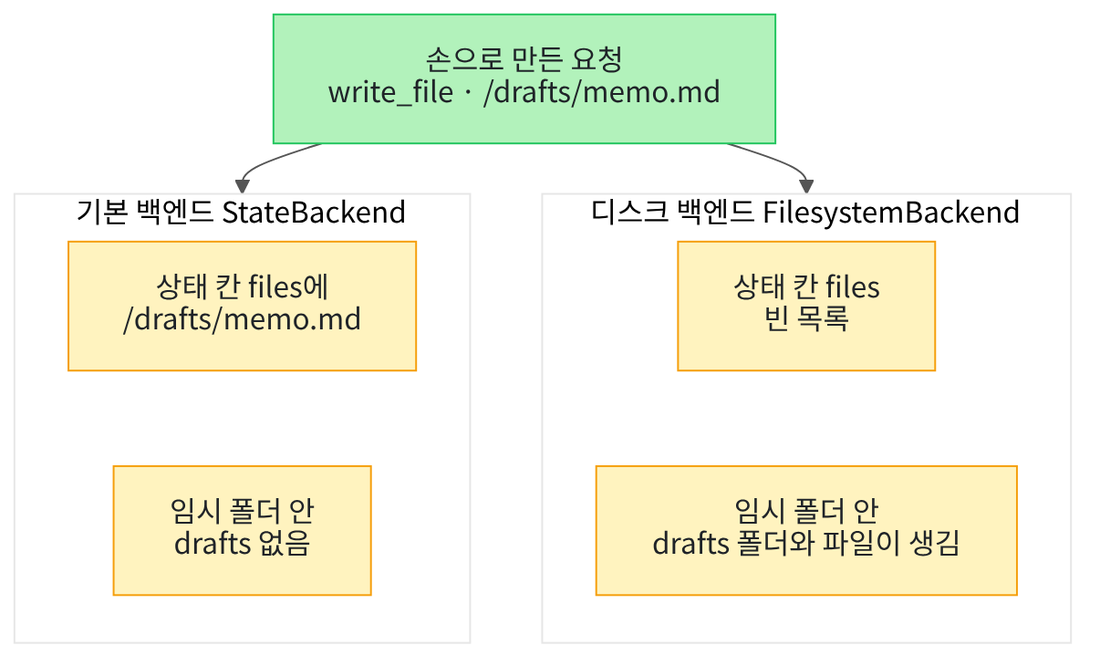

## 1. 준비

이 절에서는 02절에서 정의한 백엔드를 바꿔 가며, 파일 도구가 쓴 파일이 어디에 남는지 봅니다.
중간 결과는 긴 일을 하는 도중에 만들어, 나중에 다시 쓸 값입니다.
이 절에서는 찾은 규정을 적어 둔 메모가 중간 결과입니다.

첫 셀은 패키지 다섯을 설치하고 설치된 판 번호를 출력합니다.
설치에는 몇십 초가 걸릴 수 있습니다.

In [1]:
# 이 절에서 쓰는 패키지를 설치하고 버전을 확인합니다
%pip install -q "deepagents==0.7.0" "langchain==1.4.0" "langchain-openai==1.6.0" "langgraph==1.2.11" "python-dotenv==1.2.3"
from importlib.metadata import version

print("deepagents:", version("deepagents"))
print("langchain:", version("langchain"))
print("langchain-openai:", version("langchain-openai"))
print("langgraph:", version("langgraph"))
print("python-dotenv:", version("python-dotenv"))

Note: you may need to restart the kernel to use updated packages.
deepagents: 0.7.0
langchain: 1.4.0
langchain-openai: 1.6.0
langgraph: 1.2.11
python-dotenv: 1.2.3


**결과 읽기** — 출력 줄 `deepagents: 0.7.0`과 `langgraph: 1.2.11`이 보입니다.
다섯 판 모두 실습 폴더 잠금과 같은 판입니다.
패키지 langgraph는 3절에서 작은 그래프를 직접 만들려고 설치 목록에 넣었습니다.

다음 셀은 이 절에서 쓸 이름을 가져옵니다.
백엔드 `FilesystemBackend`와 상태 형식 `FilesystemState`는 이 절에서 처음 씁니다.
함수 `supports_execution`과 `wrap_model_call`은 02절처럼 씁니다.
마지막 가져오기 줄은 앞에서 배운 함수 다섯을 도구 파일 `harness_tools.py`에서 가져옵니다.

In [2]:
# Deep Agents(01절)·백엔드와 상태 형식(이 절 처음)·미들웨어(Ch 22)·모델·메시지·도구·그래프 이름을 가져옵니다
from deepagents import create_deep_agent
from deepagents.backends import FilesystemBackend
from deepagents.middleware.filesystem import FilesystemState, supports_execution
from langchain.agents.middleware import ModelCallLimitMiddleware, wrap_model_call
from langchain.chat_models import init_chat_model
from langchain.messages import AIMessage, HumanMessage
from langchain.tools import tool
from langgraph.graph import END, START, StateGraph
# 앞 챕터와 01절에서 배운 함수 다섯은 도구 파일에서 가져옵니다
from harness_tools import estimate_cost, show_messages, sum_usage, tool_call_names, tool_names

print("도구 파일에서 가져온 함수:", "estimate_cost, show_messages, sum_usage, tool_call_names, tool_names")

도구 파일에서 가져온 함수: estimate_cost, show_messages, sum_usage, tool_call_names, tool_names


**결과 읽기** — 출력 줄 `도구 파일에서 가져온 함수: estimate_cost, show_messages, sum_usage, tool_call_names, tool_names`가 보입니다.
다섯 함수의 뜻은 02절 1절에 적었습니다.
앞에서 배운 함수는 `harness_tools.py`에 모아 두었고, 파일을 열면 코드를 볼 수 있습니다.
커널이 `notebooks/` 폴더에서 시작해야 이 파일을 가져올 수 있습니다.

API 키가 있는지 확인합니다. `True` 값이 나오면 다음으로 넘어갑니다.

In [3]:
# .env 파일에서 OpenAI API 키를 읽습니다(키 값은 출력하지 않습니다)
import os
from dotenv import find_dotenv, load_dotenv

env_path = find_dotenv(usecwd=True)
load_dotenv(env_path)
has_key = os.getenv("OPENAI_API_KEY") is not None
print("OPENAI_API_KEY 설정 여부:", has_key)
assert has_key, "프로젝트 폴더의 .env 파일에 OPENAI_API_KEY를 적어 주세요."

OPENAI_API_KEY 설정 여부: True


실습에 쓸 모델을 준비합니다.
temperature 값을 0으로 두어 매번 비슷한 답을 고르게 합니다.

In [4]:
# 실습에 쓸 모델을 준비합니다
model = init_chat_model(
    "openai:gpt-5.4-mini",
    temperature=0,
    reasoning_effort="none",
)
print("모델 이름:", model.model_name)
print("temperature:", model.temperature)

모델 이름: gpt-5.4-mini
temperature: 0.0


**결과 읽기** — 모델 이름 `gpt-5.4-mini`, temperature `0.0`이 보이면 준비가 끝났습니다.
이 노트북의 출력은 2026-09-28에 이 모델로 실행한 결과입니다.
temperature 값을 0으로 두어도, 실행마다 답 문장이 달라질 수 있습니다.
이 셀은 모델 객체만 만들고, 모델 요청은 아직 보내지 않습니다.
모델 요청은 5절 실행 셀에서만 나갑니다.

2·3절은 이 객체로 Deep Agent를 만들기만 하고, 모델을 부르지 않습니다.
다음 셀은 파일을 쓸 빈 임시 폴더를 Ch 23 01절처럼 만듭니다.
Ch 23과 달리 작업 위치는 옮기지 않습니다.
파일을 둘 폴더는 백엔드에 직접 넘겨 정하기 때문입니다.

In [5]:
# 파일을 쓸 빈 임시 폴더를 만듭니다(Ch 23 01절 모양 — 작업 위치는 옮기지 않음)
import os
import tempfile

# mkdtemp()는 운영체제 임시 폴더 안에 새 폴더를 만들고, 그 폴더의 위치를 글로 내놓습니다
work_folder = tempfile.mkdtemp(prefix="ch27-04-")
print("임시 폴더 이름에 ch27-04-가 들어 있는가:", "ch27-04-" in work_folder)
print("임시 폴더 안 이름:", os.listdir(work_folder))

임시 폴더 이름에 ch27-04-가 들어 있는가: True
임시 폴더 안 이름: []


**결과 읽기** — 출력 줄 `임시 폴더 이름에 ch27-04-가 들어 있는가: True`가 보입니다.
라벨 `임시 폴더 안 이름:` 뒤는 빈 목록이라, 빈 폴더를 새로 만들었습니다.
폴더 위치는 컴퓨터마다 달라 출력하지 않고, 폴더 안 이름만 봅니다.
실행할 때마다 새 폴더가 생기므로, 이 노트북이 쓴 파일만 보입니다.

## 2. 디스크에 쓰는 백엔드를 직접 부르기

02절에서 백엔드는 파일 도구가 파일을 실제로 두는 자리를 정하는 부품이라고 했습니다.
기본 백엔드 `StateBackend`는 파일을 그래프 상태 안에 두고, 디스크에는 쓰지 않습니다.
이 절에서 처음 쓰는 백엔드 `FilesystemBackend`는 컴퓨터 디스크의 폴더에 실제 파일을 씁니다.

백엔드가 파일 위치의 맨 앞 `/`로 삼는 폴더를 기준 폴더라고 부르겠습니다.
아파트 안내문의 「101호」가 그 아파트 안의 101호를 뜻하는 것과 같습니다.
이 절 코드에서는 인자 `root_dir=`에 넘긴 임시 폴더가 기준 폴더입니다.
다음 셀은 이 백엔드를 만들고, 설정 두 가지를 봅니다.

In [6]:
# 임시 폴더를 기준 폴더(root_dir)로 삼는 디스크 백엔드를 만듭니다(에이전트에는 아직 넘기지 않음)
disk_backend = FilesystemBackend(root_dir=work_folder)
print("백엔드 종류:", type(disk_backend).__name__)
print("virtual_mode 값:", disk_backend.virtual_mode)
print("명령을 실행할 수 있는가:", supports_execution(disk_backend))

백엔드 종류: FilesystemBackend
virtual_mode 값: True
명령을 실행할 수 있는가: False


**결과 읽기** — 출력 줄 `백엔드 종류: FilesystemBackend`와 `virtual_mode 값: True`가 보입니다.
설정 `virtual_mode`의 기본값 `True`는 파일 위치를 기준 폴더 아래로 묶는 설정입니다.
출력 줄 `명령을 실행할 수 있는가: False`도 보입니다.
이 백엔드도 명령을 실행하지 못해, 02절처럼 모델이 받는 목록에서 `execute`가 빠질 것입니다.

다음 셀은 중간 결과로 둘 규정 메모 글을 정하고, 백엔드에 직접 씁니다.
파일 도구 없이 백엔드만 부르는 모양입니다.
메서드 `write`는 파일 위치와 글을 받아, 결과 객체 하나를 내놓습니다.

In [7]:
# 중간 결과로 둘 규정 메모 글을 정하고, 백엔드의 메서드 write로 파일 위치 /notes/rules.md에 직접 씁니다
note_text = "# 규정 메모\n대출: 1인 5권까지 14일\n연장: 반납 예정일 전에 한 번, 7일\n연체: 연체한 일수만큼 새 대출 제한\n"
write_result = disk_backend.write("/notes/rules.md", note_text)
print("쓰기 결과 종류:", type(write_result).__name__)
print("오류:", write_result.error)
print("쓴 파일 위치:", write_result.path)

쓰기 결과 종류: WriteResult
오류: None
쓴 파일 위치: /notes/rules.md


**결과 읽기** — 출력 줄 `쓰기 결과 종류: WriteResult`와 `오류: None`이 보입니다.
결과 객체의 칸 `error`가 `None`이면 쓰기에 성공한 것입니다.
출력 줄 `쓴 파일 위치: /notes/rules.md`는 우리가 넘긴 파일 위치 그대로입니다.
설치판 `backends/filesystem.py` 495~530행에서, 없는 폴더는 백엔드가 먼저 만듭니다.

다음 셀은 운영체제 함수로 임시 폴더 안을 직접 봅니다.
함수 `os.listdir`는 Ch 23 01절처럼 폴더 안 이름 목록을 내놓습니다.
함수 `os.path.join`은 폴더 위치와 이름을 운영체제에 맞는 구분 기호로 잇습니다.

In [8]:
# 운영체제 함수로 임시 폴더 안을 직접 봅니다(폴더 이름은 출력하지 않고, 폴더 안 이름만)
print("임시 폴더 안 이름:", os.listdir(work_folder))
# os.path.join은 폴더 위치와 이름을 운영체제에 맞는 구분 기호로 잇습니다
notes_folder = os.path.join(work_folder, "notes")
print("notes 폴더 안 이름:", os.listdir(notes_folder))

임시 폴더 안 이름: ['notes']
notes 폴더 안 이름: ['rules.md']


**결과 읽기** — 출력 줄 `임시 폴더 안 이름: ['notes']`와 `notes 폴더 안 이름: ['rules.md']`가 보입니다.
파일 위치 `/notes/rules.md`가 기준 폴더 안 `notes/rules.md`가 되었습니다.

다음 셀은 백엔드를 거치지 않고, Ch 2 05절에서 배운 `with open`으로 그 파일을 읽습니다.
백엔드 밖에서도 읽힌다면, 디스크에 실제 파일이 있다는 뜻입니다.

In [9]:
# 백엔드를 거치지 않고, Ch 2 05절처럼 with open으로 디스크의 파일을 직접 읽습니다
notes_file = os.path.join(notes_folder, "rules.md")
with open(notes_file, encoding="utf-8") as file:
    disk_text = file.read()
print("디스크 파일 글자 수:", len(disk_text))
print("쓴 글과 같은가:", disk_text == note_text)

디스크 파일 글자 수: 67
쓴 글과 같은가: True


**결과 읽기** — 출력 줄 `디스크 파일 글자 수: 67`과 `쓴 글과 같은가: True`가 보입니다.
백엔드가 쓴 파일을 보통의 파일 읽기로 그대로 읽었습니다.
이 파일은 노트북을 닫아도 임시 폴더에 남습니다.

이제 파일 위치 규칙을 둘 봅니다.
Linux·macOS 컴퓨터에서 `/etc`는 맨 위 폴더 바로 아래의 설정 폴더입니다.
다음 셀은 파일 위치 `/etc/rules.md`에 써 보고, 파일이 어디에 생기는지 봅니다.
실행 전에 예상해 봅니다.

In [10]:
# 파일 위치 규칙 하나: 맨 앞 /는 컴퓨터의 맨 위 폴더가 아니라 기준 폴더를 뜻합니다
etc_result = disk_backend.write("/etc/rules.md", note_text)
print("쓴 파일 위치:", etc_result.path)
top_names = os.listdir(work_folder)
top_names.sort()
print("임시 폴더 안 이름:", top_names)

쓴 파일 위치: /etc/rules.md
임시 폴더 안 이름: ['etc', 'notes']


**결과 읽기** — 출력 줄 `쓴 파일 위치: /etc/rules.md`와 `임시 폴더 안 이름: ['etc', 'notes']`가 보입니다.
컴퓨터의 `/etc`가 아니라, 기준 폴더 안에 `etc` 폴더가 새로 생겼습니다.
설정 `virtual_mode`가 `True`이면 파일 위치의 맨 앞 `/`는 기준 폴더를 뜻합니다.
메서드 `sort`로 이름을 가나다·알파벳 차례로 맞춰, 출력 차례가 컴퓨터마다 달라지지 않게 했습니다.

파일 위치에 `..`를 넣으면 한 단계 위 폴더, 곧 기준 폴더 밖을 가리킵니다.
다음 셀은 그런 파일 위치로 써 보고, 받은 오류를 출력합니다.
Ch 2 05절처럼 `try`·`except`로 그 오류 이름만 받아, 셀은 끝까지 실행됩니다.

In [11]:
# 파일 위치 규칙 둘: ..로 기준 폴더 밖을 가리키면, 쓰기 전에 오류로 막히는지 봅니다(Ch 2 05절 try/except)
try:
    disk_backend.write("../outside.md", note_text)
except ValueError as error:
    print("받은 오류:", type(error).__name__, "|", error)

받은 오류: ValueError | Path traversal not allowed


**결과 읽기** — 출력 줄 `받은 오류: ValueError | Path traversal not allowed`가 보입니다.
영어 글은 위 폴더로 거슬러 오르는 파일 위치를 허용하지 않는다는 뜻입니다.
설치판 `backends/filesystem.py` 202~206행에서, 백엔드는 파일을 쓰기 전에 이 오류를 냅니다.
그래서 기준 폴더 밖에는 아무것도 쓰지 않았습니다.

## 3. 같은 요청을 두 백엔드에 넣어 보기

이번에는 백엔드를 직접 부르지 않고, Deep Agent의 파일 도구 `write_file`을 부릅니다.
모델 없이 도구를 부르려고, 01절 6절처럼 도구 실행 노드만 든 작은 그래프를 만듭니다.
상태 형식은 01절과 달리 Deep Agents가 준 `FilesystemState`를 씁니다.
이 형식은 Ch 21 03절의 라이브러리 상태 형식 `AgentState`에 파일 칸 `files`를 더한 것입니다.
기본 백엔드는 파일을 이 칸에 쓰므로, 칸이 없는 상태 형식으로는 받을 수 없습니다.

다음 셀은 Deep Agent 하나를 받아, 그 도구 실행 노드만 든 작은 그래프를 내놓는 함수입니다.
01절 6절 셀의 흐름을 함수 하나로 묶었습니다.

In [12]:
# Deep Agent 하나를 받아, 그 도구 실행 노드 하나만 든 작은 그래프를 만들어 내놓습니다(상태 형식은 files 칸이 있는 FilesystemState)
def tools_only_graph(agent):
    builder = StateGraph(FilesystemState)
    builder.add_node("tools", agent.nodes["tools"].bound)
    builder.add_edge(START, "tools")
    builder.add_edge("tools", END)
    return builder.compile()

**결과 읽기** — 정의 셀이라 출력이 없습니다.
속성 `agent.nodes["tools"].bound`는 01절에서 본 도구 실행 노드입니다.
도구 실행 노드는 그래프 밖에서 따로 부를 수 없어, 이렇게 작은 그래프에 넣어 부릅니다.

다음 셀은 기본 백엔드와 디스크 백엔드로 Deep Agent를 하나씩 만듭니다.
인자 `backend=`에 2절의 디스크 백엔드 객체를 그대로 넘깁니다.
두 Deep Agent의 도구 실행 노드로 작은 그래프도 하나씩 만듭니다.

In [13]:
# 기본 백엔드와 디스크 백엔드로 Deep Agent를 하나씩 만들고, 작은 그래프를 하나씩 만듭니다(요청은 보내지 않음)
state_agent = create_deep_agent(model=model)
disk_agent = create_deep_agent(model=model, backend=disk_backend)
print("두 Deep Agent의 도구가 같은가:", tool_names(state_agent) == tool_names(disk_agent))
state_tools_graph = tools_only_graph(state_agent)
disk_tools_graph = tools_only_graph(disk_agent)
small_graph = state_tools_graph.get_graph()
print("작은 그래프의 노드:", list(small_graph.nodes))

두 Deep Agent의 도구가 같은가: True
작은 그래프의 노드: ['__start__', 'tools', '__end__']


**결과 읽기** — 출력 줄 `두 Deep Agent의 도구가 같은가: True`가 보입니다.
백엔드를 바꿔도 도구 이름은 그대로이고, 바뀌는 것은 파일을 두는 자리뿐입니다.
라벨 `작은 그래프의 노드:` 뒤에는 시작과 끝 사이에 `tools` 하나만 있습니다.

다음 셀은 모델 없이 `write_file` 요청 하나를 담은 응답을 손으로 만듭니다.
Ch 20 01절과 01절 6절처럼, 칸 `name`·`args`·`id`·`type`을 적은 딕셔너리를 넣습니다.
파일 위치는 2절과 다른 `/drafts/memo.md`로 정해, 새로 생기는 폴더가 보이게 했습니다.

In [14]:
# 모델 없이, write_file 요청 하나를 담은 응답을 손으로 만듭니다(01절 6절 모양)
memo_args = {"file_path": "/drafts/memo.md", "content": note_text}
memo_call = {"name": "write_file", "args": memo_args, "id": "hand_write_1", "type": "tool_call"}
memo_request = AIMessage(content="", tool_calls=[memo_call])
print("요청한 도구:", tool_call_names(memo_request))

요청한 도구: ['write_file']


**결과 읽기** — 출력 줄 `요청한 도구: ['write_file']`이 보입니다.
응답 하나에 도구 요청 하나를 담았습니다.

호출 ID `hand_write_1`과 글 `note_text`는 우리가 정한 값입니다.
다음 셀은 이 요청을 기본 백엔드 쪽 작은 그래프에 넣습니다.
실행 전에 예상해 봅니다.
기본 백엔드라면 파일은 상태 칸 `files`에 들어가고, 임시 폴더는 그대로일 것입니다.

In [15]:
# 기본 백엔드 쪽 작은 그래프에 넣고, 도구 메시지·상태 칸 files·임시 폴더 안을 봅니다
state_result = state_tools_graph.invoke({"messages": [memo_request]})
state_message = state_result["messages"][-1]
print("도구 메시지:", state_message.content, "|", state_message.status)
print("상태 칸 files의 파일 위치:", list(state_result["files"]))
top_names = os.listdir(work_folder)
top_names.sort()
print("임시 폴더 안 이름:", top_names)

도구 메시지: Updated file /drafts/memo.md | success
상태 칸 files의 파일 위치: ['/drafts/memo.md']
임시 폴더 안 이름: ['etc', 'notes']


**결과 읽기** — 출력 줄 `도구 메시지: Updated file /drafts/memo.md | success`가 보입니다.
출력 줄 `상태 칸 files의 파일 위치: ['/drafts/memo.md']`에서, 파일은 상태 칸에 들어갔습니다.
출력 줄 `임시 폴더 안 이름: ['etc', 'notes']`는 앞과 같아, `drafts` 폴더는 생기지 않았습니다.
설치판 `backends/state.py` 98~122행에서, 기본 백엔드는 디스크 대신 그래프의 `files` 칸에 씁니다.

다음 셀은 상태 칸 `files`에 든 파일 항목 하나를 봅니다.

In [16]:
# 상태 칸 files에 든 파일 항목 하나의 칸 이름과 글을 봅니다(시각 칸의 값은 출력하지 않음)
memo_entry = state_result["files"]["/drafts/memo.md"]
print("파일 항목의 칸:", list(memo_entry))
print("쓴 글과 같은가:", memo_entry["content"] == note_text)

파일 항목의 칸: ['content', 'encoding', 'created_at', 'modified_at']
쓴 글과 같은가: True


**결과 읽기** — 출력 줄 `파일 항목의 칸: ['content', 'encoding', 'created_at', 'modified_at']`이 보입니다.
칸 `content`가 글이고, `encoding`은 글자를 적는 방식입니다.
나머지 두 칸은 만든 시각과 고친 시각이라, 실행마다 달라져 값을 출력하지 않았습니다.
출력 줄 `쓴 글과 같은가: True`로, 상태 칸에 우리 글이 그대로 들어간 것을 봅니다.

### 값 바꿔 보기: 디스크 백엔드

바꿀 값은 작은 그래프의 백엔드 하나이고, 넣는 요청은 같습니다.
실행 전에 예상해 봅니다.
디스크 백엔드라면 상태 칸 `files`는 비고, 임시 폴더에 `drafts` 폴더가 생길 것입니다.

In [17]:
# 값 바꿔 보기: 같은 요청을 디스크 백엔드 쪽 작은 그래프에 넣고 같은 것을 봅니다
disk_result = disk_tools_graph.invoke({"messages": [memo_request]})
disk_message = disk_result["messages"][-1]
print("도구 메시지:", disk_message.content, "|", disk_message.status)
print("상태 칸 files의 파일 위치:", list(disk_result["files"]))
top_names = os.listdir(work_folder)
top_names.sort()
print("임시 폴더 안 이름:", top_names)

도구 메시지: Updated file /drafts/memo.md | success
상태 칸 files의 파일 위치: []
임시 폴더 안 이름: ['drafts', 'etc', 'notes']


**결과 읽기** — 출력 줄 `도구 메시지: Updated file /drafts/memo.md | success`는 앞 셀과 같습니다.
출력 줄 `상태 칸 files의 파일 위치: []`에서, 상태 칸은 비어 있습니다.
출력 줄 `임시 폴더 안 이름: ['drafts', 'etc', 'notes']`에서, `drafts` 폴더가 새로 생겼습니다.
같은 요청이 같은 도구 메시지를 냈지만, 파일이 남은 자리는 백엔드에 따라 달랐습니다.

## 4. 실제 모델을 부를 준비

5절에서는 02절의 자료실 규정 도구로, 모델이 찾은 규정을 파일에 적게 합니다.
다음 셀은 02절 2절의 규정 글 셀과 같은 글입니다.

In [18]:
# 도구가 찾을 교재용 규정 글 넷을 주제어마다 정합니다(실제 도서관 규정이 아님)
library_rules = {
    "대출": "일반 도서는 1인 5권까지 14일 동안 대출할 수 있습니다.",
    "연장": "반납 예정일 전에 한 번, 7일 연장할 수 있습니다. 예약한 사람이 있는 책은 연장할 수 없습니다.",
    "연체": "연체한 일수만큼 새 대출이 제한됩니다.",
    "운영": "평일은 09:00~20:00, 토요일은 10:00~17:00에 운영합니다.",
}
print("규정 주제어:", list(library_rules))

규정 주제어: ['대출', '연장', '연체', '운영']


**결과 읽기** — 출력 줄 `규정 주제어: ['대출', '연장', '연체', '운영']`이 보입니다.
02절과 같은 교재용 규정이고, 실제 도서관 규정이 아닙니다.

다음 셀도 02절의 도구 셀과 같은 글입니다.
맨 위 `@tool` 줄이 아래 함수를 도구로 등록하는 것도 02절과 같습니다.

In [19]:
# 주제어 하나로 규정 글 하나를 찾는 도구를 만듭니다(맨 @tool 줄 — Ch 19 01절)
@tool
def lookup_rule(topic: str):
    """교육센터 자료실 규정 하나를 주제어로 찾습니다. topic에는 대출, 연장, 연체, 운영 가운데 하나를 넣습니다."""
    # 없는 주제어면 오류 대신 정해 둔 안내 글을 내놓습니다
    if topic in library_rules:
        return library_rules[topic]
    return "그런 주제어의 규정은 없습니다. 대출, 연장, 연체, 운영 가운데 하나를 넣어 주세요."

**결과 읽기** — 정의 셀이라 출력이 없습니다.
도구 `lookup_rule`은 주제어 하나로 규정 글 하나를 찾고, 없는 주제어에는 넣을 수 있는 주제어를 알려 주는 정해 둔 글을 내놓습니다.

다음 셀은 03절 셀과 같은 글의 바깥 호출 한도입니다.
규정을 찾고, 파일에 적고, 답하는 흐름이라 02절의 3보다 넉넉한 10을 그대로 씁니다.

In [20]:
# 바깥 에이전트의 모델 요청을 열 번까지로 막는 호출 한도를 만듭니다(02절 셀과 한도만 다름)
outer_limit = ModelCallLimitMiddleware(run_limit=10, exit_behavior="end")
print("바깥 호출 한도:", outer_limit.run_limit)

바깥 호출 한도: 10


**결과 읽기** — 출력 줄 `바깥 호출 한도: 10`이 보입니다.
주석의 「02절 셀과 한도만 다름」은 이 셀을 처음 쓴 03절에서 적은 말입니다.

다음 셀은 02절과 같은 글의 general-purpose 명세이고, 자기 호출 한도는 2입니다.
01절에서 본 것처럼 바깥 호출 한도는 이 서브에이전트로 옮겨 가지 않아, 두 곳에 따로 줍니다.

In [21]:
# 기본 서브에이전트와 같은 이름의 명세를 만들고, 그 안에 자기 호출 한도 둘을 넣습니다(01절 6절 모양)
helper_limit = ModelCallLimitMiddleware(run_limit=2, exit_behavior="end")
helper_spec = {
    "name": "general-purpose",
    "description": "교재용 도우미입니다. 맡긴 일을 짧게 처리합니다.",
    "system_prompt": "맡긴 일을 두 문장의 한국어로 처리하세요.",
    "middleware": [helper_limit],
}
print("명세의 키:", list(helper_spec))

명세의 키: ['name', 'description', 'system_prompt', 'middleware']


**결과 읽기** — 출력 줄 `명세의 키: ['name', 'description', 'system_prompt', 'middleware']`가 보입니다.
한 번 실행의 모델 요청은 10에, 도구 `task`를 부른 횟수 × 2를 더한 값을 넘지 않습니다.

다음 셀은 02절과 같은 글의 기록 훅입니다.
모델 요청이 나갈 때마다, 모델이 받은 도구 이름을 기록 목록 `seen_tool_lists`에 붙입니다.

In [22]:
# 모델 요청이 나갈 때마다, 그 요청에 실린 도구 이름을 기록 목록에 붙이는 훅입니다(Ch 22 02절 기록 훅 모양)
@wrap_model_call
def record_tool_names(request, handler):
    names = []
    for item in request.tools:
        names.append(item.name)
    seen_tool_lists.append(names)
    # 기록만 하고, 요청은 그대로 모델에게 보냅니다
    return handler(request)

**결과 읽기** — 정의 셀이라 출력이 없습니다.
기록 목록은 실행 셀에서 새로 만듭니다.
이 훅은 바깥 인자 `middleware=`에만 넣어, general-purpose의 요청은 적지 않습니다.

## 5. 모델이 중간 결과를 파일로 적는 실행

모델 실행에는 2·3절과 다른 새 임시 폴더를 씁니다.
모델이 쓴 파일만 보이게 하려는 것입니다.

In [23]:
# 모델 실행에 쓸 새 임시 폴더와, 그 폴더를 기준 폴더로 삼는 디스크 백엔드를 만듭니다
run_folder = tempfile.mkdtemp(prefix="ch27-04-")
run_backend = FilesystemBackend(root_dir=run_folder)
print("새 임시 폴더 안 이름:", os.listdir(run_folder))

새 임시 폴더 안 이름: []


**결과 읽기** — 라벨 `새 임시 폴더 안 이름:` 뒤는 빈 목록입니다.
이 폴더가 5절 디스크 백엔드의 기준 폴더입니다.

다음 셀은 이 백엔드와 4절의 부품을 넘겨 Deep Agent를 만듭니다.
02절 `rule_agent`와 같은 모양에 인자 `backend=`를 더했고, 바깥 한도는 03절의 10입니다.

In [24]:
# 이 백엔드와 우리 도구·호출 한도·기록 훅·명세를 넘겨 Deep Agent를 만듭니다(요청은 아직 보내지 않음)
run_agent = create_deep_agent(
    model=model,
    tools=[lookup_rule],
    backend=run_backend,
    middleware=[outer_limit, record_tool_names],
    subagents=[helper_spec],
)
run_tools = tool_names(run_agent)
print("그래프에 등록된 도구 수:", len(run_tools))

그래프에 등록된 도구 수: 10


**결과 읽기** — 출력 줄 `그래프에 등록된 도구 수: 10`이 보입니다.
기본 도구 아홉과 우리 도구 하나이고, 02절 `rule_agent`와 같은 수입니다.

질문은 규정 셋을 찾아 파일 `/notes/rules.md`에 적어 두고, 안내문을 쓰라는 글입니다.
파일 위치를 질문이 정해 준 것은 흐름을 보여 주려고 실행 전에 정한 예입니다.
실행 전에 예상해 봅니다.
모델은 규정을 찾은 뒤 `write_file`로 메모를 적고, 도구 요청 없는 답으로 끝낼 것입니다.

In [25]:
# 기록 목록을 새로 만들고, 규정을 찾아 파일에 적어 두라는 질문 한 줄로 한 번 실행합니다
seen_tool_lists = []
question = "교육센터 자료실의 대출, 연장, 연체 규정을 찾아, 찾은 규정 글을 /notes/rules.md 파일에 적어 두세요. 그다음 처음 온 학생에게 줄 안내문을 세 문장으로 써 주세요."
first_input = {"messages": [HumanMessage(content=question)]}
input_count = len(first_input["messages"])
run_result = run_agent.invoke(first_input)
run_messages = run_result["messages"]
print("결과 메시지 수:", len(run_messages))

결과 메시지 수: 8


**결과 읽기** — 라벨 `결과 메시지 수:` 뒤에 이번 실행의 메시지 수가 보입니다.
넣은 질문 하나 뒤에 모델 응답과 도구 메시지가 더해졌습니다.

이번 실행에서는 `결과 메시지 수: 8`이었습니다.
모델이 규정을 몇 개 함께 찾았는지에 따라 달라지는 값입니다.
노트북 밖 다섯 번에서는 여덟이 세 번, 아홉이 두 번이었습니다.
새 커널로 한 번 더 실행했을 때도 여덟이었습니다.

다음 셀은 결과 메시지를 Ch 19 06절 함수 `show_messages`로 봅니다.

In [26]:
# 결과 메시지를 차례로 봅니다(Ch 19 06절 함수 show_messages)
print("결과 메시지:")
show_messages(run_messages)

결과 메시지:
HumanMessage
AIMessage | 도구 호출 요청: ['lookup_rule', 'lookup_rule', 'lookup_rule']
ToolMessage | 결과 상태: success | 내용: 일반 도서는 1인 5권까지 14일 동안 대출할 수 있습니다.
ToolMessage | 결과 상태: success | 내용: 반납 예정일 전에 한 번, 7일 연장할 수 있습니다. 예약한 사람이 있는 책은 연장할 수 없습니다.
ToolMessage | 결과 상태: success | 내용: 연체한 일수만큼 새 대출이 제한됩니다.
AIMessage | 도구 호출 요청: ['write_file']
ToolMessage | 결과 상태: success | 내용: Updated file /notes/rules.md
AIMessage | 도구 호출 요청: []


**결과 읽기** — 라벨 줄 아래 둘째 줄이 첫 응답이고, 도구 호출 요청에는 `lookup_rule`만 들어 있습니다.
그 뒤 응답 줄 `AIMessage | 도구 호출 요청: ['write_file']`이 모델이 파일을 적으려 한 자리입니다.
바로 아래 줄 `ToolMessage | 결과 상태: success | 내용: Updated file /notes/rules.md`가 도구 결과입니다.
마지막 줄은 도구 요청이 없는 답입니다.

이번 실행에서 첫 응답은 `lookup_rule`을 세 번 함께 요청했고, 주제어는 대출·연장·연체였습니다.
노트북 밖 다섯 번 가운데 두 번은 묻지 않은 운영 규정까지 네 번 요청했습니다.
몇 개를 요청하든 모두 첫 응답 한 번에 넣은 것은 다섯 번 모두 같았습니다.

다음 셀은 이번 실행이 더한 응답에서 `write_file` 요청의 인자를 모읍니다.
응답의 속성 `tool_calls`에서 이름이 `write_file`인 요청만 고릅니다.

In [27]:
# 이번 실행이 더한 응답에서 write_file 요청의 인자를 모으고, 파일 위치를 봅니다
run_new = run_messages[input_count:]
written_args = []
for message in run_new:
    if type(message).__name__ == "AIMessage":
        for call in message.tool_calls:
            if call["name"] == "write_file":
                written_args.append(call["args"])
print("write_file 요청 수:", len(written_args))
for args in written_args:
    print("적으려 한 파일 위치:", args["file_path"])

write_file 요청 수: 1
적으려 한 파일 위치: /notes/rules.md


**결과 읽기** — 출력 줄 `write_file 요청 수: 1`과 `적으려 한 파일 위치: /notes/rules.md`가 보입니다.
모델은 질문이 정한 파일 위치에 한 번 적었습니다.
요청을 몇 번, 어느 파일 위치로 보낼지는 모델이 정하는 값입니다.
노트북 밖 다섯 번에서도 모두 같은 파일 위치에 한 번 적었습니다.

다음 셀은 결과의 상태 칸 `files`와 임시 폴더 안을 봅니다.
3절의 값 바꿔 보기에서 본 대로라면, 상태 칸은 비고 임시 폴더에 파일이 생길 것입니다.

In [28]:
# 디스크 백엔드 쪽 결과의 상태 칸 files와, 임시 폴더 안 이름을 봅니다
print("상태 칸 files의 파일 위치:", list(run_result["files"]))
run_names = os.listdir(run_folder)
run_names.sort()
print("임시 폴더 안 이름:", run_names)

상태 칸 files의 파일 위치: []
임시 폴더 안 이름: ['notes']


**결과 읽기** — 출력 줄 `상태 칸 files의 파일 위치: []`와 `임시 폴더 안 이름: ['notes']`가 보입니다.
디스크 백엔드라 상태 칸은 비었고, 모델이 적은 파일은 임시 폴더에 생겼습니다.
3절에서 손으로 만든 요청으로 본 자리와 같습니다.

다음 셀은 모델이 적은 파일 위치마다, 임시 폴더 안 파일을 `with open`으로 읽습니다.
메서드 `lstrip("/")`은 글 맨 앞의 `/`를 떼어 냅니다.
함수 `os.path.isfile`은 그 위치에 파일이 있으면 `True`를 내놓습니다.

In [29]:
# 모델이 적은 파일 위치마다, 임시 폴더 안 실제 파일을 with open으로 읽어 요청 인자의 글과 견줍니다
for args in written_args:
    # 메서드 lstrip("/")은 파일 위치 맨 앞의 /를 떼어, 임시 폴더 안 상대 이름으로 만듭니다
    disk_path = os.path.join(run_folder, args["file_path"].lstrip("/"))
    print("임시 폴더 안에 파일이 있는가:", os.path.isfile(disk_path))
    if os.path.isfile(disk_path):
        with open(disk_path, encoding="utf-8") as file:
            run_text = file.read()
        print("요청 인자의 글과 같은가:", run_text == args["content"])

임시 폴더 안에 파일이 있는가: True
요청 인자의 글과 같은가: True


**결과 읽기** — 출력 줄 `임시 폴더 안에 파일이 있는가: True`와 `요청 인자의 글과 같은가: True`가 보입니다.
모델이 요청 인자로 보낸 글이 디스크 파일에 그대로 적혔습니다.
같은 글은 메시지 목록 안 응답의 `write_file` 요청 인자에도 남아 있습니다.
파일로 적어 두어도 이번 실행의 메시지 목록에서 그 글이 빠지지는 않습니다.

## 6. 요청 수와 예상 비용

이 실행도 도구 `task`를 부르지 않아, 모델 요청은 모두 바깥 에이전트의 것입니다.
02절처럼 응답으로 센 요청 수와 기록 훅이 센 요청 수를 견주고, 받은 도구도 봅니다.

In [30]:
# 이번 실행이 더한 메시지만 Ch 19 05절 함수 sum_usage로 세고, 기록 훅이 센 요청 수·받은 도구와 견줍니다
run_usage = sum_usage(run_new)
print("응답으로 센 요청 수:", run_usage["requests"])
print("기록 훅이 센 요청 수:", len(seen_tool_lists))
print("받은 도구 수:", len(seen_tool_lists[0]))
print("execute를 받았는가:", "execute" in seen_tool_lists[0])
print("입력 토큰:", run_usage["input_tokens"], "| 출력 토큰:", run_usage["output_tokens"])

응답으로 센 요청 수: 3
기록 훅이 센 요청 수: 3
받은 도구 수: 9
execute를 받았는가: False
입력 토큰: 6093 | 출력 토큰: 284


**결과 읽기** — 라벨 `응답으로 센 요청 수:`와 `기록 훅이 센 요청 수:` 뒤의 수가 같습니다.
요청 수는 도구를 요청한 응답 수에 마지막 응답 하나를 더한 값입니다.
출력 줄 `받은 도구 수: 9`와 `execute를 받았는가: False`도 보입니다.
2절에서 예상한 대로, 디스크 백엔드에서도 모델은 `execute`를 받지 않았습니다.

이번 실행에서는 요청 3번, `입력 토큰: 6093 | 출력 토큰: 284`였습니다.
도구를 요청한 응답이 둘이라, 셈으로도 3번입니다.
노트북 밖 다섯 번과 새 커널 두 번에서 요청은 모두 3번이었습니다.
출력 토큰은 노트북 밖 다섯 번에서 실행마다 달랐습니다.

다음 셀은 02절과 같은 글의 셀로, 이번 실행의 예상 비용을 셉니다.
요금은 과정 요금표(2026-09-17)의 100만 토큰당 달러이고, 예상 비용은 청구 금액이 아닙니다.

In [31]:
# 2026-09-17 요금표(100만 토큰당 달러)로 이번 실행의 예상 비용을 셉니다(Ch 6 06절 함수 estimate_cost)
input_rate = 0.75
cached_input_rate = 0.075
output_rate = 4.50
run_cost = estimate_cost(run_usage, input_rate, cached_input_rate, output_rate)
rounded_cost = round(run_cost, 6)
print("예상 비용(달러):", rounded_cost)

예상 비용(달러): 0.005848


**결과 읽기** — 라벨 `예상 비용(달러):` 뒤에 이번 실행의 어림값이 보입니다.
토큰 수가 실행마다 달라, 이 값도 달라질 수 있습니다.
합친 사용량에는 캐시 입력 칸이 없어, 입력 토큰을 모두 입력 요금으로 셉니다.

이번 실행에서는 `예상 비용(달러): 0.005848`이었습니다.
노트북 밖 다섯 번에서는 0.005843에서 0.006201 사이였습니다.
캐시 입력을 빼지 않은 어림이라, 청구 금액은 이보다 작을 수 있습니다.

## 정리

1. 디스크 백엔드는 기준 폴더 안에 실제 파일을 쓰고, 기본 백엔드는 상태 칸 `files`에 둡니다.
2. 파일 위치의 맨 앞 `/`는 기준 폴더를 뜻하고, `..`로 밖을 가리키면 쓰기 전에 막힙니다.
3. 도구 `write_file`로 적은 글은 파일에도 남고, 요청 인자로 이번 실행의 메시지 목록에도 남습니다.

05절에서는 아주 긴 도구 결과를 파일로 옮기는 장치를 봅니다.
메시지 목록에는 짧은 안내 글만 남습니다.